# GenQAI demo: one forward pass instead of a VQE loop

A Hamiltonian-conditioned transformer (a hackathon reproduction of Quantinuum–NVIDIA–Pfizer's ADAPT-GQE)
reads the qubit Hamiltonian of a molecular geometry it has **never seen** and writes out a complete
circuit: which excitation operators to apply, in which order, and with which rotation angles. There is no
variational optimisation at inference time. Everything below is computed live when you run it.

**Run:** *Kernel → Restart & Run All* (about 1 minute for H2, longer with IonQ queueing).
IonQ cells run only when `IONQ_API_KEY` is set (environment variable or a `.env` file in the repo root).

## 0. Setup
Finds the repo (or clones it), installs any missing dependencies, and checks for an IonQ API key.
PySCF and PyTorch are optional: without PySCF only stored grid geometries are available, and without PyTorch
the notebook replays precomputed circuits (clearly labelled as such).

In [1]:
import importlib.util, os, shutil, subprocess, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=DeprecationWarning)
REPO_URL = "https://github.com/EpameinondasDouros/quantinuum-nvidia-pfizer-hpc"
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "genqai" / "demo.py").exists()), None)
if ROOT is None:  # notebook uploaded on its own: fetch the repo (code, data, checkpoints)
    ROOT = Path.cwd() / "quantinuum-nvidia-pfizer-hpc"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))


def pip_install(*pkgs):
    if importlib.util.find_spec("pip"):
        cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    elif shutil.which("uv"):
        cmd = ["uv", "pip", "install", "-q", "-p", sys.executable, *pkgs]
    else:
        raise RuntimeError(f"no pip available to install {pkgs}")
    return subprocess.run(cmd).returncode == 0


REQUIRED = {"qiskit": "qiskit>=2.0", "qiskit_nature": "qiskit-nature==0.8.*", "qiskit_aer": "qiskit-aer>=0.15",
            "qiskit_ionq": "qiskit-ionq>=1.0", "dotenv": "python-dotenv", "scipy": "scipy",
            "matplotlib": "matplotlib", "pylatexenc": "pylatexenc"}
OPTIONAL = {"pyscf": "pyscf>=2.6", "torch": "torch>=2.2"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing", missing)
    pip_install(*missing)
for mod, pkg in OPTIONAL.items():
    if importlib.util.find_spec(mod) is None and not pip_install(pkg):
        print(f"WARNING: {mod} unavailable -> degraded mode (see the markdown above)")
importlib.invalidate_caches()

import qiskit
from genqai.demo import torch_available
from genqai.measure import ionq_available

HAVE_IONQ = ionq_available()  # reads IONQ_API_KEY from the environment or ROOT/.env; never printed
print(f"repo: {ROOT}\nqiskit {qiskit.__version__} | pyscf: {importlib.util.find_spec('pyscf') is not None} | "
      f"torch: {torch_available()} | IonQ key found: {HAVE_IONQ}")

repo: /Users/udsy/PycharmProjects/qollab-hack-GenQAI/.claude/worktrees/agent-a34660952567c1f30
qiskit 2.5.2 | pyscf: True | torch: True | IonQ key found: True


## 1. Pick a molecule and an unseen geometry
Choose a system and type **any** bond length in Å (H4 is a linear chain with spacings `(a, b, a)`, so give
`(a, b)`). The default, H2 at r = 1.33 Å, lies off the dataset grid and inside the held-out interval
1.2–1.45 Å that the model never trained on. The Hamiltonian and the HF / CCSD / FCI references are computed
live with PySCF.

In [2]:
SYSTEM = "h2"          # "h2" (2 qubits), "lih4" (4), "lih6" (6), "h4" (8)
GEOMETRY = (1.33,)     # Å; e.g. lih4: (2.47,), h4: (1.05, 1.37)
RUN_ADAPT = True       # also run ADAPT-VQE live for the cost comparison (seconds for h2/lih4, minutes for h4)
RUN_IONQ = True        # use the IonQ cloud simulator if a key is present
SHOTS = 4000           # total shots per backend, split over the measurement groups
IONQ_NOISE_MODELS = ["aria-1", "forte-1"]

In [3]:
from genqai.data import load_hamiltonians
from genqai.demo import get_record

record, how = get_record(SYSTEM, GEOMETRY)
train = load_hamiltonians(SYSTEM, "train")
print(f"{SYSTEM} {record.geometry_params}: {how}")
print(f"{record.num_qubits} qubits, {len(record.pauli_terms)} Pauli terms, {record.mapping} mapping")
for k in record.geometry_params:
    v = sorted({r.geometry_params[k] for r in train})
    print(f"training geometries: {len(train)}, {k} in [{v[0]}, {v[-1]}] Å")
print(f"HF   {record.hf_energy:.6f} Ha\nCCSD {record.ccsd_energy:.6f} Ha\nFCI  {record.fci_energy:.6f} Ha  (exact target)")

h2 {'r': 1.33}: built live with PySCF in 0.3s (not in any training data)
2 qubits, 5 Pauli terms, parity mapping
training geometries: 10, r in [0.5, 2.1] Å
HF   -0.963549 Ha
CCSD -1.029046 Ha
FCI  -1.029046 Ha  (exact target)


## 2. Generate the circuit in one shot
Every checkpoint found in `checkpoints/<system>/` (SFT, and GRPO / distilled ones if present) reads the
Hamiltonian and emits operators + angles greedily: one model call, zero energy evaluations.

== sft: live from checkpoints/h2/sft.pt in 9 ms
   1 operators | 4 CX, depth 15 (Qiskit CX basis) | IonQ Aria native: 4 MS gates
  0  op   2  double [0, 2]->[1, 3]        theta = -0.28858 rad
circuit:


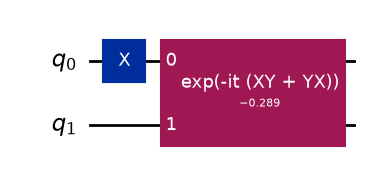

In [4]:
from genqai.circuits import build_circuit, gate_stats
from genqai.demo import describe_circuit, generate_all
from genqai.measure import compile_state, ionq_native_stats

gens = generate_all(record)
for name, (circ, info) in gens.items():
    qc = build_circuit(record, circ.operators, circ.angles)
    st = gate_stats(qc)
    nat = ionq_native_stats(compile_state(qc), "aria-1")
    print(f"== {name}: {info['mode']} from {info['checkpoint']} in {1000 * info['runtime_s']:.0f} ms")
    print(f"   {len(circ.operators)} operators | {st['cnot_count']} CX, depth {st['depth']} (Qiskit CX basis) | "
          f"IonQ Aria native: {nat['native_2q_count']} MS gates")
    print(describe_circuit(circ, max_lines=20))

circ = next(iter(gens.values()))[0]
SHOW = 6  # draw at most the HF preparation + first SHOW operators
qc = build_circuit(record, circ.operators[:SHOW], circ.angles[:SHOW])
print(f"circuit{' (first %d operators)' % SHOW if len(circ.operators) > SHOW else ''}:")
try:
    display(qc.draw("mpl", fold=-1))
except Exception:
    print(qc.draw("text", fold=-1))

## 3. Score it exactly and compare
Exact (statevector) energy of each circuit against the classical references and against what you would
otherwise do on a quantum computer: copy the nearest training geometry's circuit (with or without
re-optimising its angles), or run ADAPT-VQE from scratch. The cost columns are the point: the generator
needs **0 energy evaluations**; ADAPT needs pool-gradient sweeps and an optimiser loop.

In [5]:
from genqai.demo import compare, comparison_table

evals = compare(record, gens, live_adapt=RUN_ADAPT)
print(comparison_table(record, evals))
gen = next(e for e in evals if e.model_forward_passes)
print(f"\n{gen.method}: |error| = {abs(gen.error_mha):.3f} mHa -> chemical accuracy: "
      f"{'YES' if abs(gen.error_mha) <= 1.6 else 'NO'} with {gen.energy_evals} energy evaluations")
for e in evals:
    if e.method == "adapt":
        print(f"ADAPT-VQE: {e.pool_gradient_evals} pool gradients + {e.energy_evals} energy evaluations "
              f"+ {e.optimizer_iterations} optimiser iterations for the same geometry")

method                      energy (Ha)   err mHa chem acc #ops   CX depth model calls energy evals pool grads  time s
----------------------------------------------------------------------------------------------------------------------
hf                            -0.963549    65.497       no    0    0     1           0            0          0    0.00
ccsd                          -1.029046    -0.000      yes    0    -     -           0            0          0    0.00
fci                           -1.029046     0.000      yes    0    -     -           0            0          0    0.00
sft_oneshot                   -1.029040     0.006      yes    1    4    15           1            0          0    0.01
nn_reuse                      -1.024939     4.107       no    1    4    15           0            0          0    0.00
nn_refine                     -1.029046    -0.000      yes    1    4    15           0            5          0    0.00
adapt                         -1.029046    -0.00

## 4. Run it as a quantum measurement
The Hamiltonian is split into qubit-wise-commuting groups, each measured in its own product basis, and the
energy is reported with its standard error. Local backends: ideal shots and our simple trapped-ion
depolarising model. IonQ cloud simulator (needs the key): ideal, and IonQ's own `aria-1` / `forte-1` noise
models. H2 needs 2 groups; LiH (4 qubits) needs more shots per group for the same precision, so keep
`SHOTS` modest on the free tier.

measuring sft_oneshot: 2 groups, 4000 shots per backend



backend                energy (Ha)     stderr   err mHa  groups    shots
exact                    -1.029040   0.000000     0.006       0        0
local_shots              -1.027922   0.005752     1.124       2     4000
local_noisy              -1.017000   0.005879    12.045       2     4000
ionq_ideal               -1.028774   0.000000     0.271       2        0  job=01a12801-307c-76ac-8e44-0eba658e53f7  (1e-3 prob rounding: |bias| <= 1.1 mHa)
ionq_noisy/aria-1        -1.008408   0.006038    20.637       2     4000  job=01a12801-491a-77e2-a32e-4b7a4a0e329e
ionq_noisy/forte-1       -1.017749   0.005924    11.297       2     4000  job=01a12801-61bd-74d6-b6ff-3a0c54b773f0
local_noisy = GenQAI depolarizing approximation (NOT IonQ's model); ionq_noisy = IonQ's simulator noise model


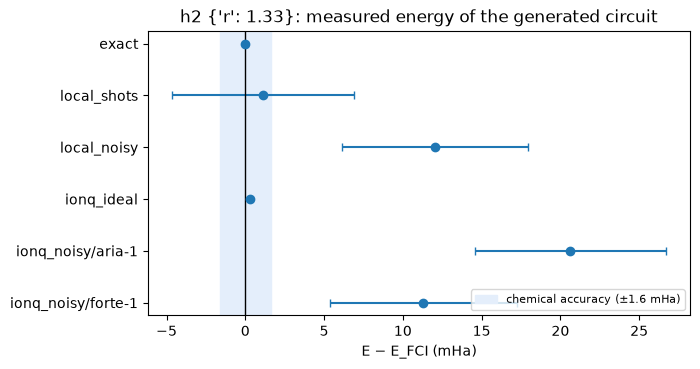

In [6]:
import matplotlib.pyplot as plt
from genqai.measure import MeasurementPlan, run_backends, runs_table

plan = MeasurementPlan.from_record(record)
backends = ["exact", "local_shots", "local_noisy"]
if RUN_IONQ and HAVE_IONQ:
    if SYSTEM != "h2":
        print(f"WARNING: {SYSTEM} has {plan.num_groups} measurement groups -> "
              f"{SHOTS // plan.num_groups} shots per group per IonQ job; this uses free-tier quota")
    backends += ["ionq_ideal", "ionq_noisy"]
elif RUN_IONQ:
    print("No IONQ_API_KEY found: local backends only. Set os.environ['IONQ_API_KEY'] and re-run this cell.")
print(f"measuring {circ.source}: {plan.num_groups} groups, {SHOTS} shots per backend\n")
runs = run_backends(record, circ.operators, circ.angles, backends, shots=SHOTS,
                    ionq_noise_models=IONQ_NOISE_MODELS, plan=plan)
print(runs_table(record, runs))

fig, ax = plt.subplots(figsize=(7, 0.45 * len(runs) + 1))
err = [1000 * (e.energy - record.fci_energy) for e in runs]
ax.axvspan(-1.6, 1.6, color="#e4eefb", label="chemical accuracy (±1.6 mHa)")
ax.errorbar(err, range(len(runs)), xerr=[1000 * e.stderr for e in runs], fmt="o", capsize=3)
ax.set_yticks(range(len(runs)), [e.meta["label"] for e in runs])
ax.invert_yaxis()
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("E − E_FCI (mHa)")
ax.set_title(f"{SYSTEM} {record.geometry_params}: measured energy of the generated circuit")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 5. Results across all geometries (committed figures)
These summarise the full evaluation (`python scripts/run_pipeline.py` regenerates them).

**fig1_pes**: Potential-energy curves (top) and error vs FCI (bottom) of the generated circuits against HF/CCSD/ADAPT.

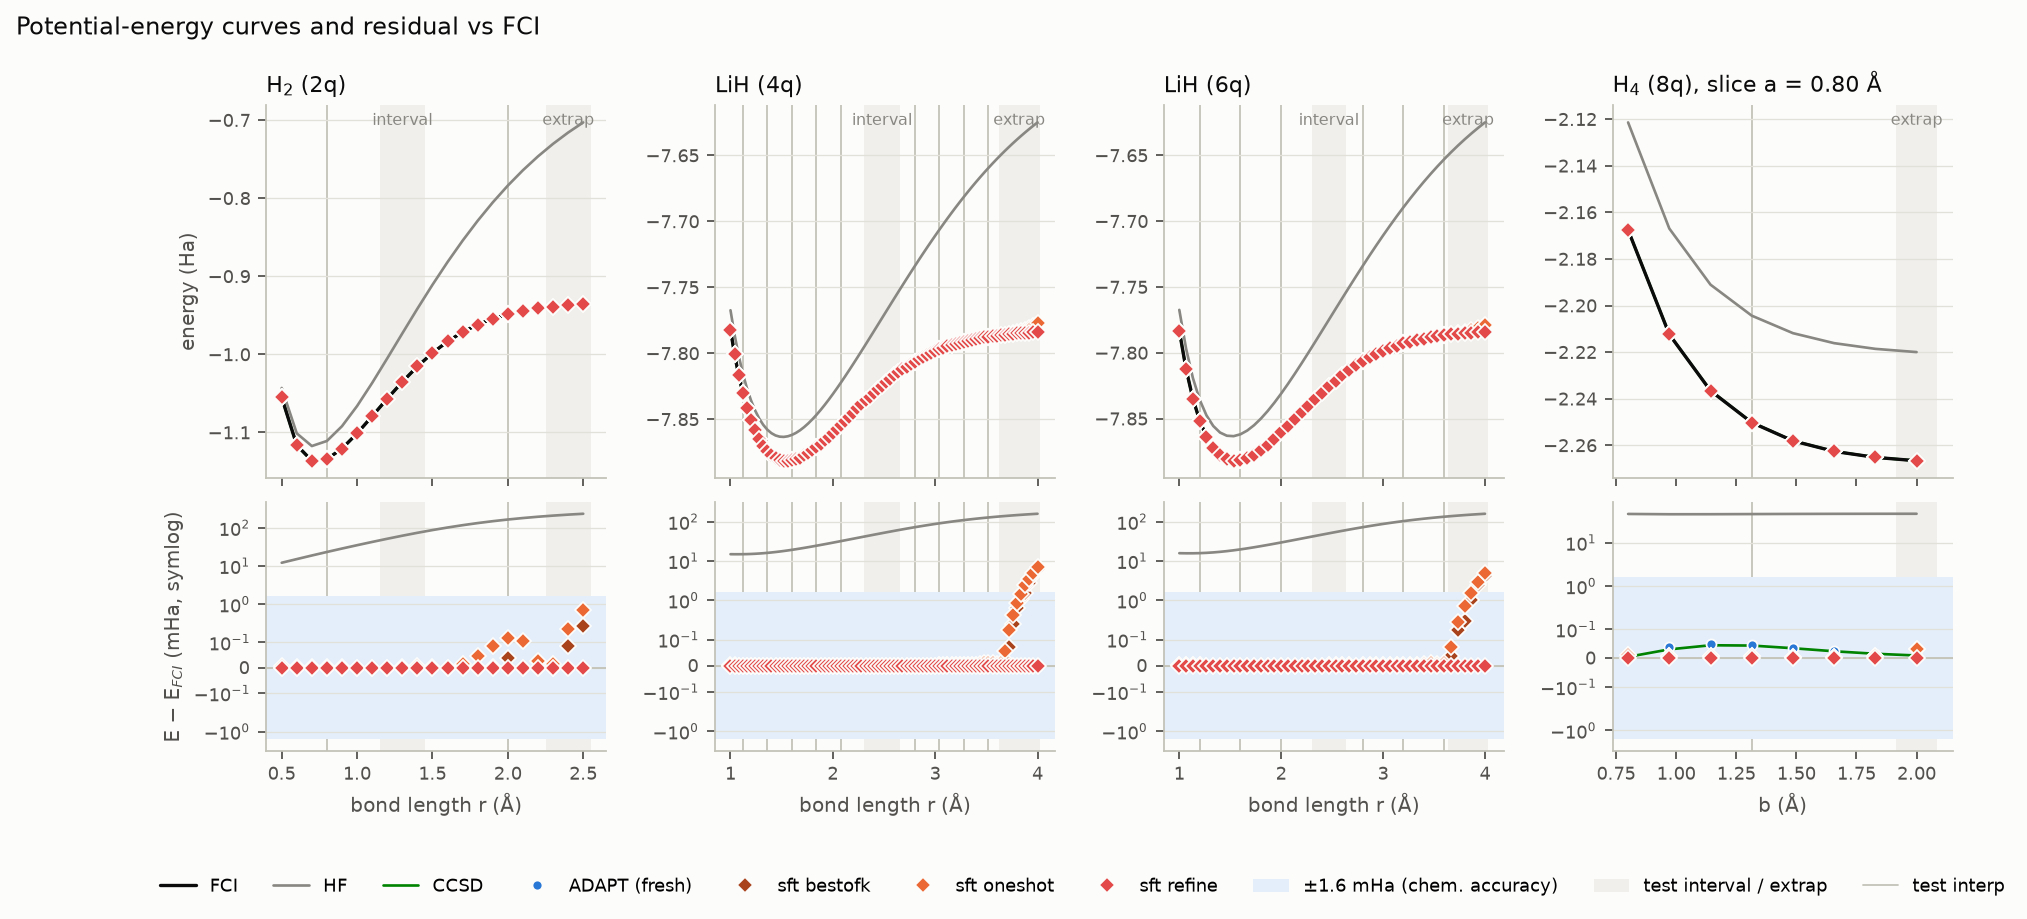

**fig2_test_errors**: Per-method |E - E_FCI| on the held-out test geometries (interp, interval, extrap).

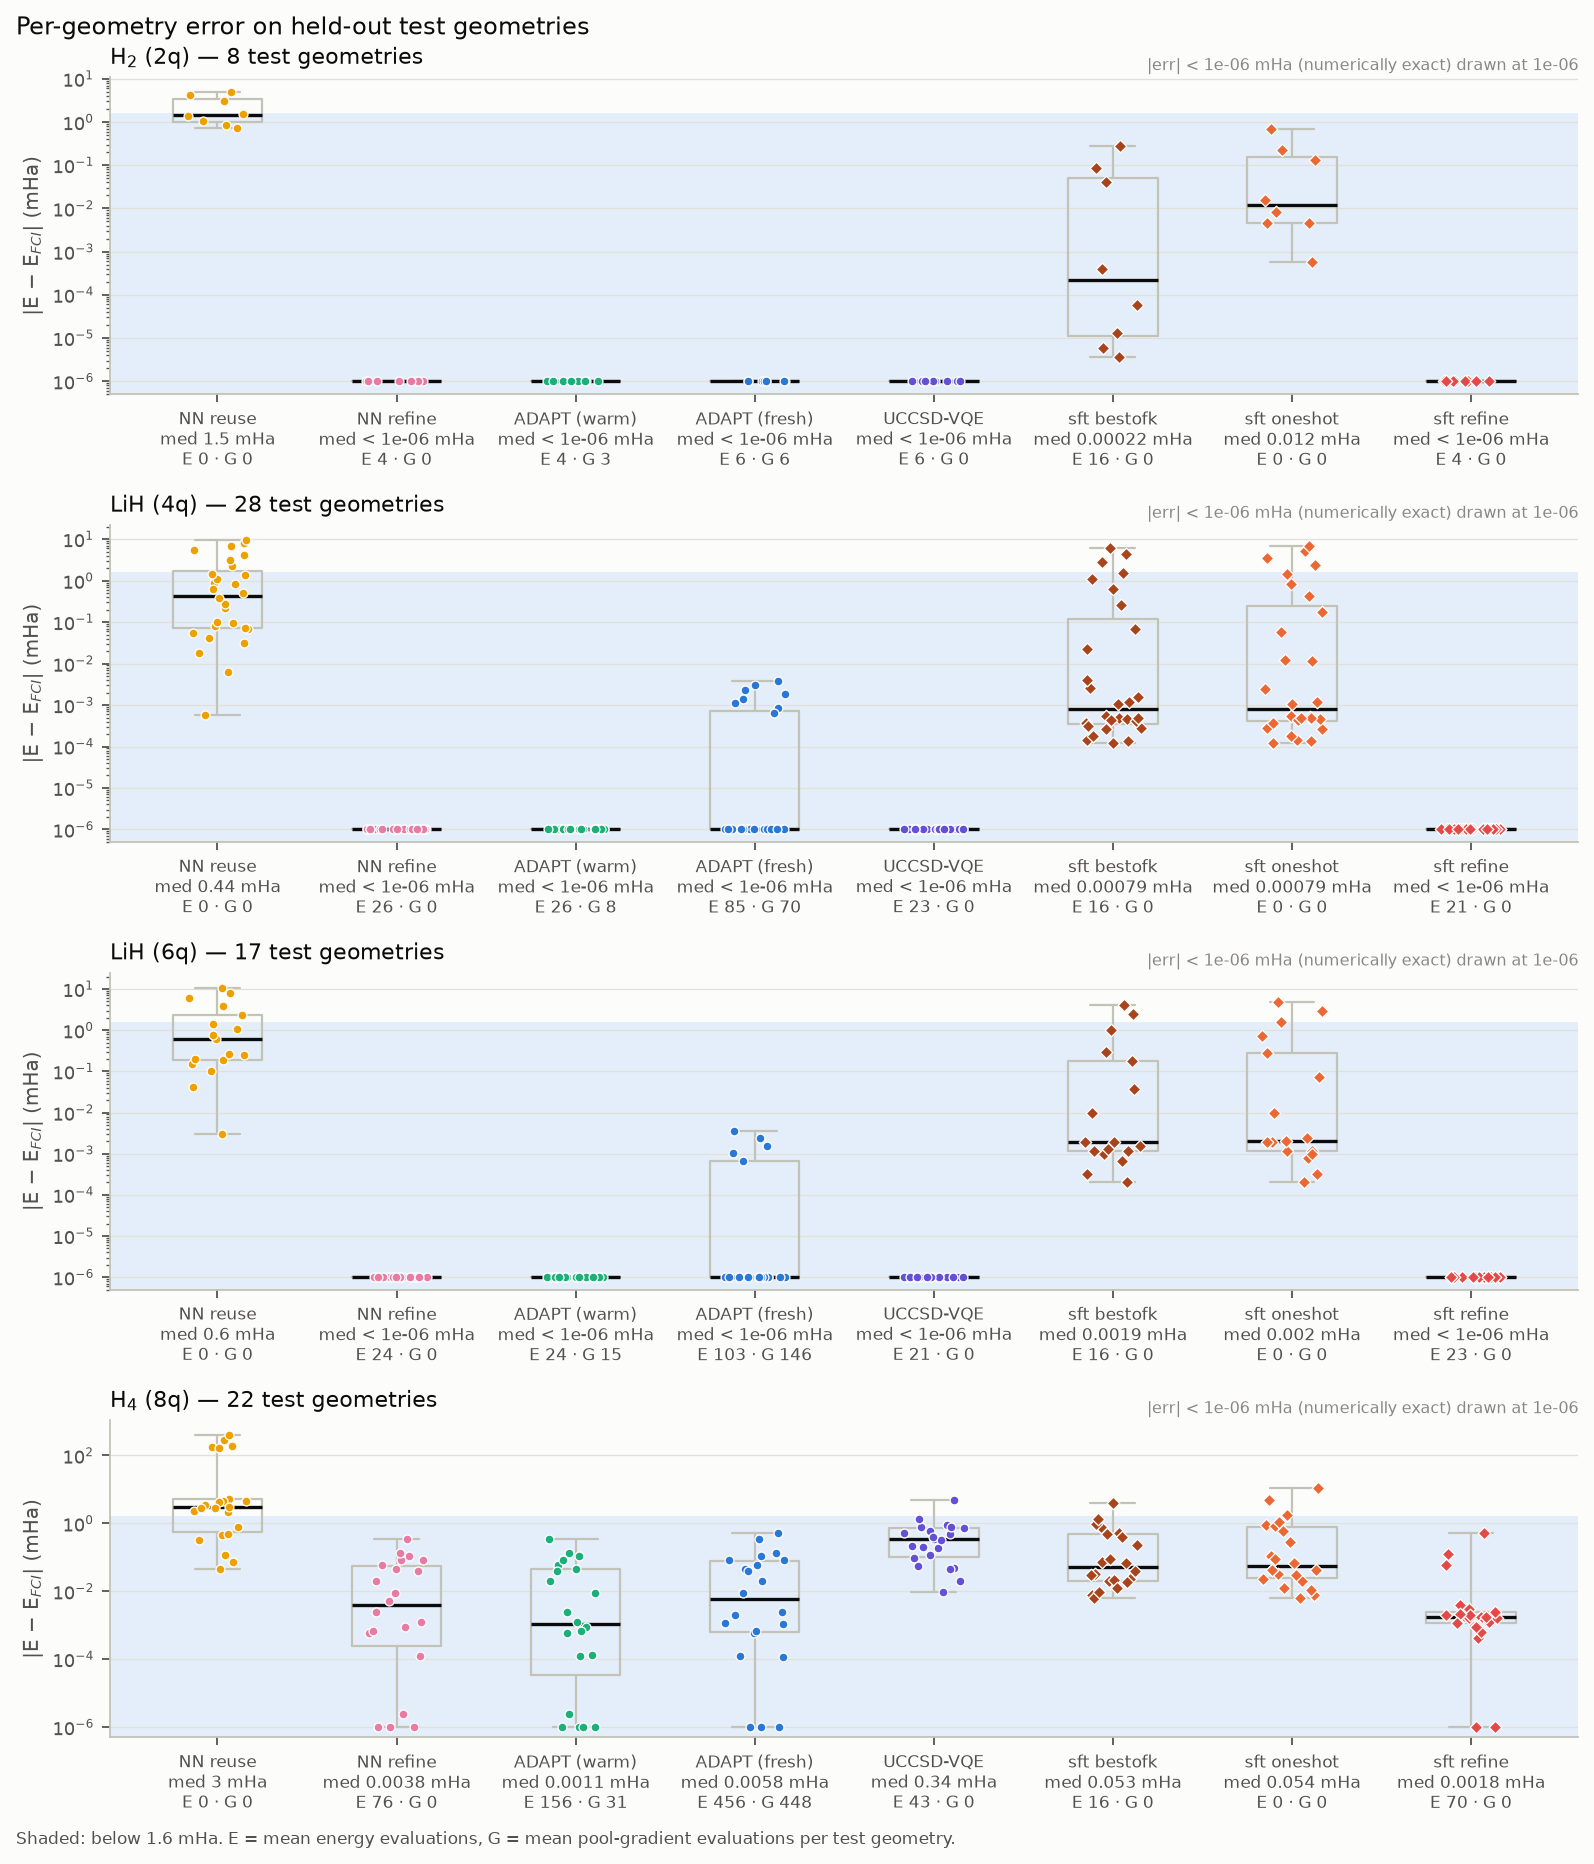

**fig3_accuracy_cost**: Median test error vs circuit size (CX) and vs quantum evaluations per geometry: one-shot = 0 evals.

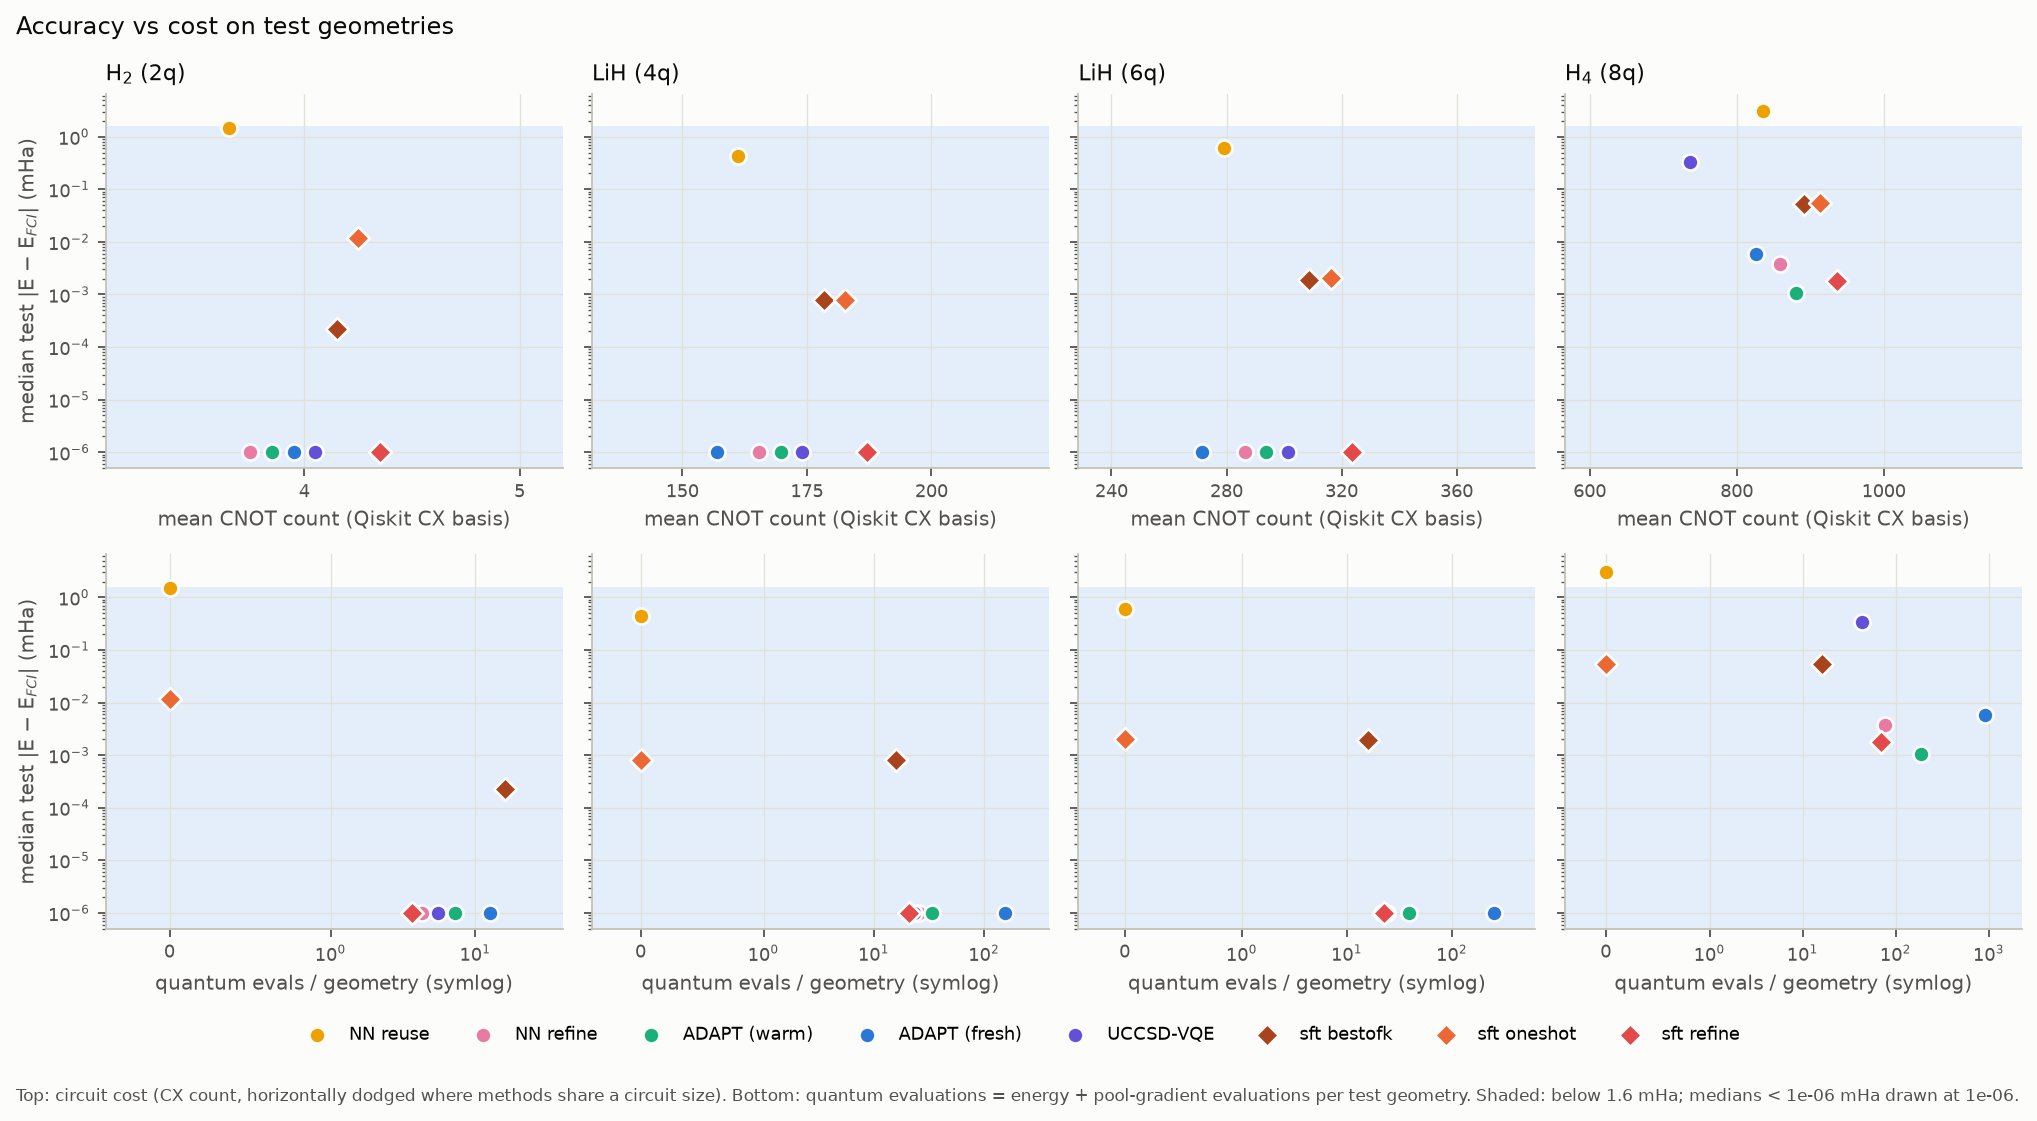

**fig4_training**: SFT training curves: validation one-shot error vs epoch.

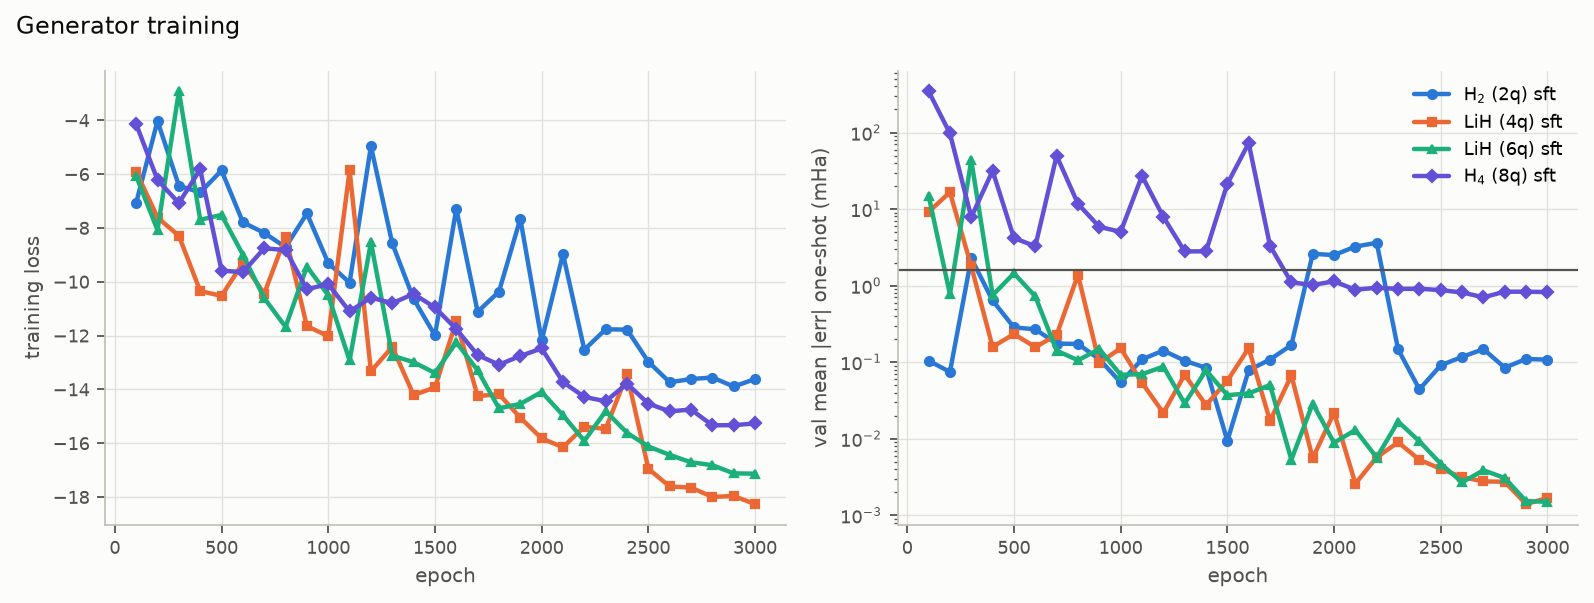

**fig5_breakeven**: Amortisation: cumulative quantum evals / wall-clock vs new geometries; dots = break-even M* vs ADAPT.

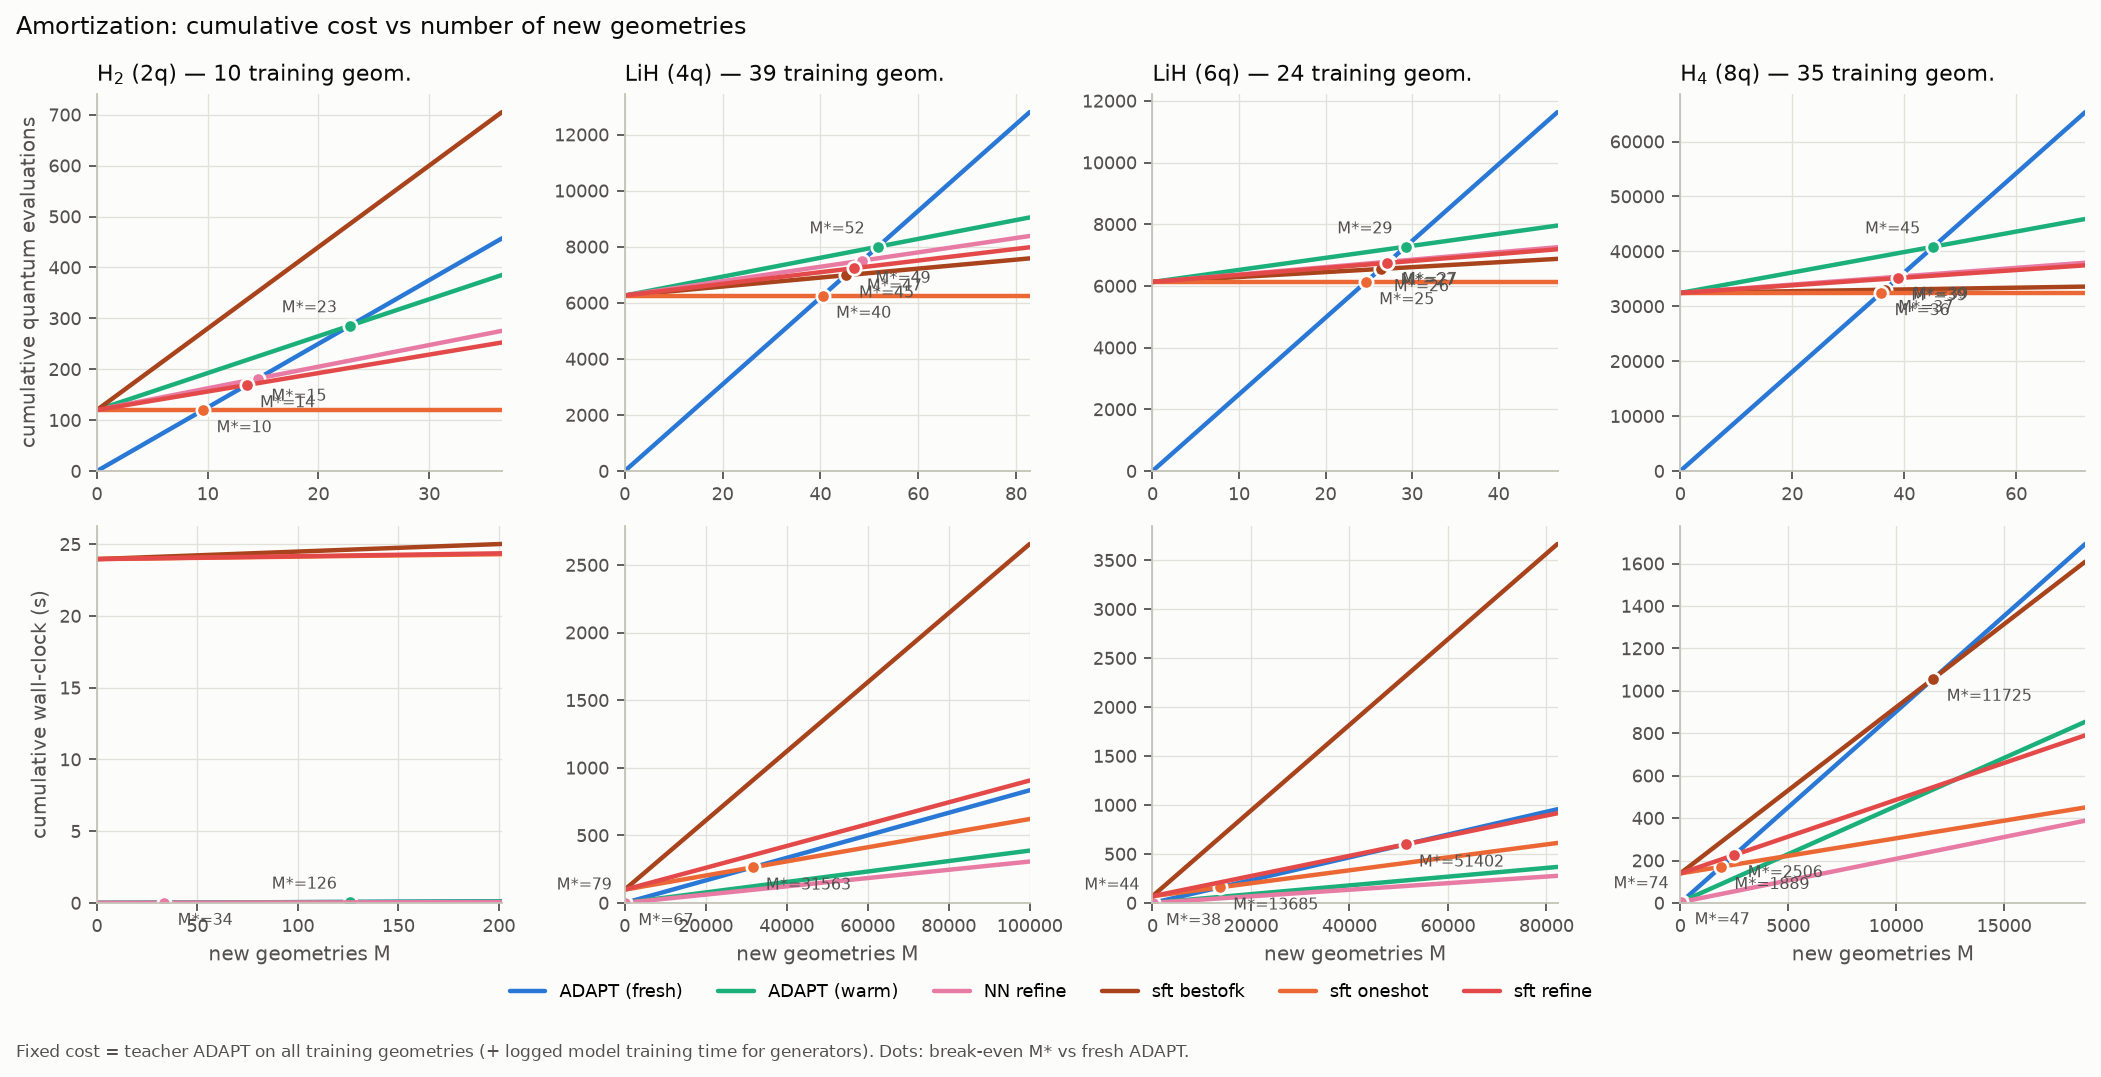

**fig6_ionq**: Measured energies on local and IonQ cloud simulators (ideal and noisy) vs FCI.

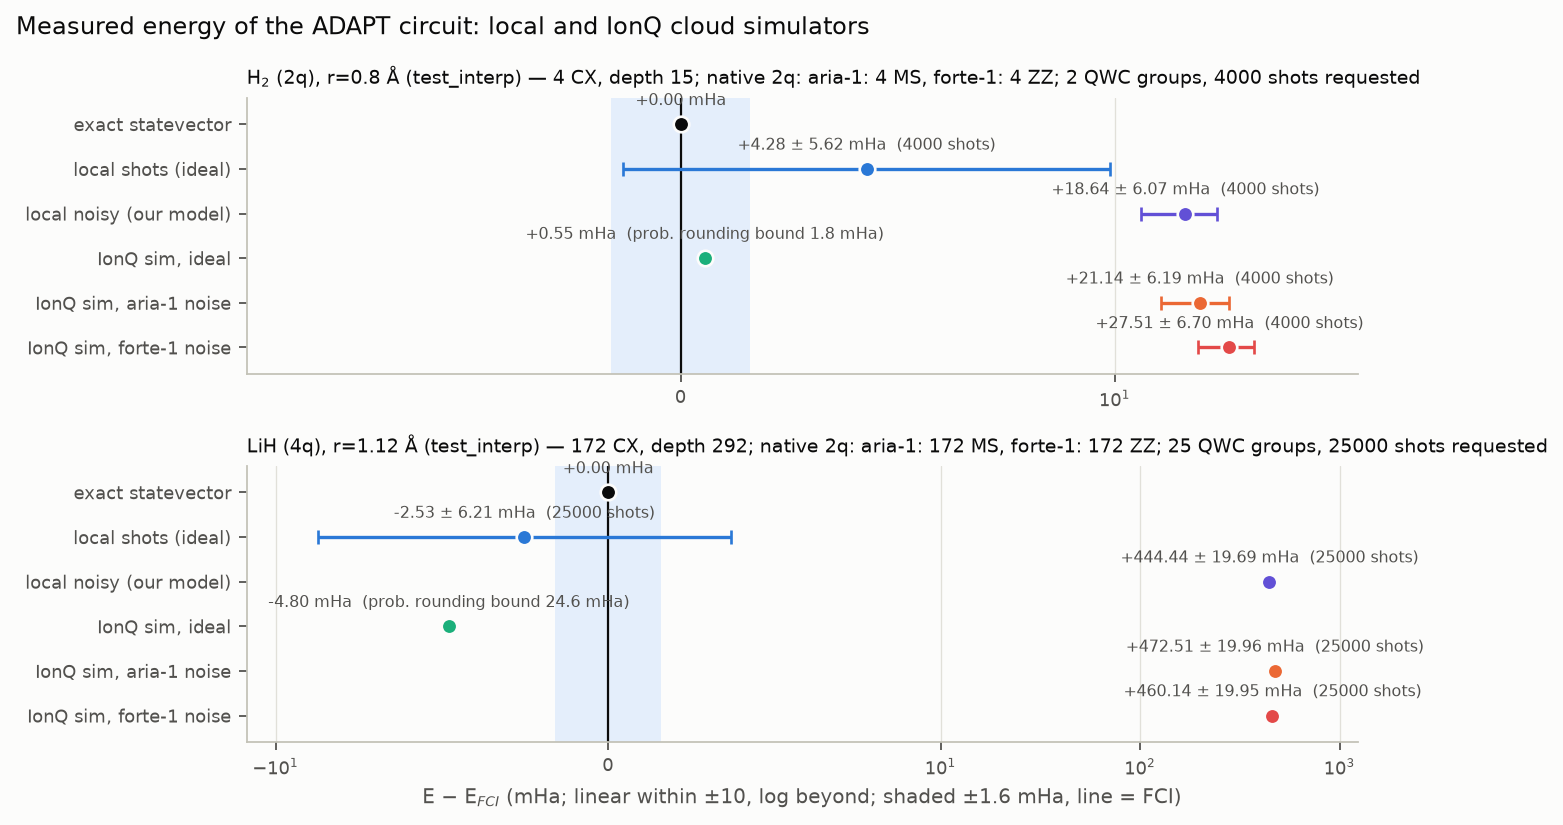

In [7]:
from IPython.display import Image, Markdown
from genqai.demo import FIGURE_CAPTIONS

for name, caption in FIGURE_CAPTIONS.items():
    p = ROOT / "figures" / f"{name}.png"
    if p.exists():
        display(Markdown(f"**{name}**: {caption}"), Image(str(p), width=900))

### Caveats
* Exact energies use a sparse statevector; "CX" is the Qiskit CX-basis count with all-to-all connectivity,
  not IonQ native gates (the native MS count above is qiskit-ionq's local compilation).
* `local_noisy` is our depolarising approximation, not IonQ's model; `ionq_ideal` returns probabilities rounded
  to 1e-3, which leaves a small bounded bias.
* One model per molecule/active space; the generator is trained only on its training-split geometries.